# BitFit
IndoBERT (`indobenchmark/indobert-base-p2`) | data sizes 5 / 10 / 50 / 100% | 5 seeds.

Only bias terms are trainable; the classification head keeps both weight and bias trainable.

In [ ]:
!pip install -q transformers==4.57.6 peft==0.18.1, datasets==5.0.1, accelerate==1.14.0
!pip install -q -U scikit-learn

import transformers, datasets, peft, accelerate, torch
print("transformers:", transformers.__version__, " (pinned)")
print("peft        :", peft.__version__, " (pinned)")
print("datasets    :", datasets.__version__, " (pinned)")
print("accelerate  :", accelerate.__version__, " (pinned)")
print("torch       :", torch.__version__, " (Colab-provided)")
print("CUDA avail  :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU         :", torch.cuda.get_device_name(0), " <- keep the same GPU type across methods")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 58.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 557.0/557.0 kB 13.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 27.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 389.2/389.2 kB 26.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 21.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 30.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import sys
sys.path.append('/content/drive/MyDrive/code')   # folder containing utils.py
from utils import *

print("Data root    :", DATA_ROOT)
print("Results file :", RESULTS_PATH)
print("Seeds        :", SEEDS)
print("Data sizes   :", DATA_SIZES)

Mounted at /content/drive
Data root    : /content/drive/MyDrive/thesis/data
Results file : /content/drive/MyDrive/thesis/results.csv
Seeds        : [42, 123, 456, 789, 2026]
Data sizes   : [100, 50, 10]


### Check data and progress

In [ ]:
validate_data_sizes()  
print()
print_status() 

 size_%                                folder  rows  actual_%_of_full  hoax_%
     10 /content/drive/MyDrive/thesis/data/10   848              10.0    50.0
     50 /content/drive/MyDrive/thesis/data/50  4244              50.0    50.0
    100    /content/drive/MyDrive/thesis/data  8486             100.0    50.0

val rows: 1212 | test rows: 2426 | full train rows: 8486
evaluation interval (steps per full-data epoch): 531
Data checks passed.

Completed seeds per (method, data size); target = 5; tag='main'
data_size  10   50   100
method                  
BitFit       0    2    5
FFT          5    5    5
LoRA         5    5    5
Total: 37 / 45 for methods present


### Model definition

In [4]:
def build_bitfit_model():
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=2, id2label=ID2LABEL, label2id=LABEL2ID
    )
    for name, param in model.named_parameters():
        if name.startswith("classifier"):
            param.requires_grad = True      # full head trainable
        elif "bias" in name:
            param.requires_grad = True      # biases everywhere else
        else:
            param.requires_grad = False

    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    print(f"trainable params: {trainable:,} || all params: {total:,} || trainable%: {100*trainable/total:.4f}")
    return model

### Run all data sizes and seeds

In [ ]:
METHOD_NAME = "BitFit"
LEARNING_RATE = 1e-3
TAG = "main"              
RUN_SIZES = DATA_SIZES   
RUN_SEEDS = SEEDS

In [6]:
for size in RUN_SIZES:
    for seed in RUN_SEEDS:
        run_experiment(
            method_name=METHOD_NAME,
            seed=seed,
            model_init_fn=build_bitfit_model,
            learning_rate=LEARNING_RATE,
            data_size=size,
            tag=TAG,
        )

print()
print_status(tag=TAG)

[skip] BitFit data=100% seed=42 tag=main already logged
[skip] BitFit data=100% seed=123 tag=main already logged
[skip] BitFit data=100% seed=456 tag=main already logged
[skip] BitFit data=100% seed=789 tag=main already logged
[skip] BitFit data=100% seed=2026 tag=main already logged
[skip] BitFit data=50% seed=42 tag=main already logged
[skip] BitFit data=50% seed=123 tag=main already logged

  BitFit | data 50% | seed 456 | tag main | lr 0.001


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

... (62 outputs left out)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p2 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


trainable params: 104,450 || all params: 124,442,882 || trainable%: 0.0839
trainable parameters: 104,450 / 124,442,882 (0.0839%)


Step,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
531,0.313800,0.352664,0.867162,0.867603,0.867162,0.867122
1062,0.153000,0.468875,0.859736,0.859877,0.859736,0.859722
1593,0.075000,0.600435,0.863036,0.863813,0.863036,0.862963
2124,0.036300,0.710023,0.864686,0.864686,0.864686,0.864686



TEST -- Acc 0.8735 | F1 0.8734 | val F1 0.8671 | VRAM 0.721 GB | 2.5 min | 2124 steps (4 evals, best @ step 531)

Completed seeds per (method, data size); target = 5; tag='main'
data_size  10   50   100
method                  
BitFit       5    5    5
FFT          5    5    5
LoRA         5    5    5
Total: 45 / 45 for methods present


### Training curves
One seed per data size (the first in `RUN_SEEDS`). X-axis is the training step; the dashed line marks the checkpoint restored for test evaluation.

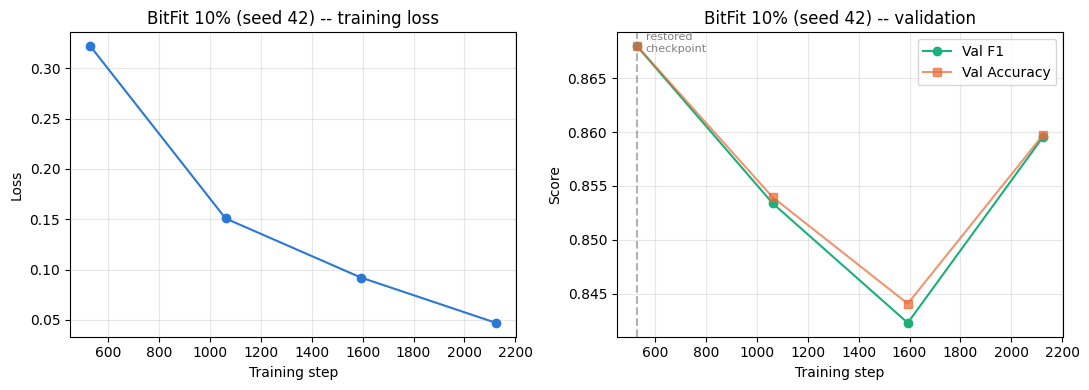

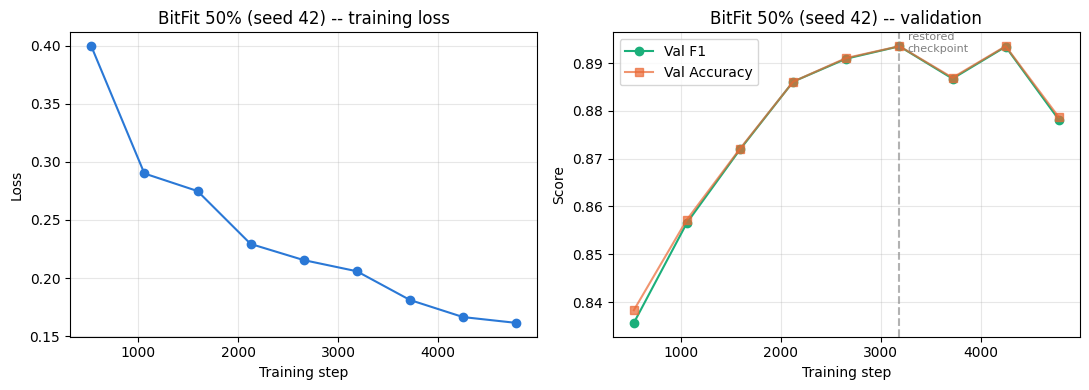

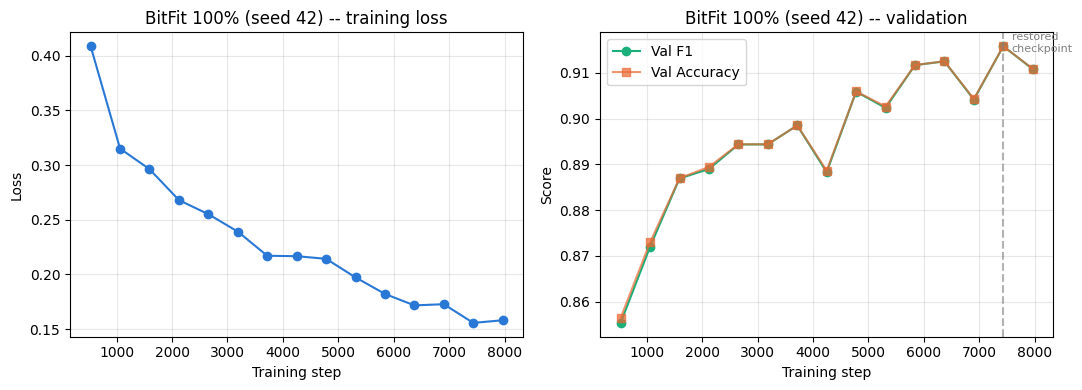

In [8]:
for size in sorted(RUN_SIZES):
    plot_training_curves(METHOD_NAME, RUN_SEEDS[0], size, TAG)

### Consistency across seeds
Validation F1 for all seeds overlaid, one chart per data size.

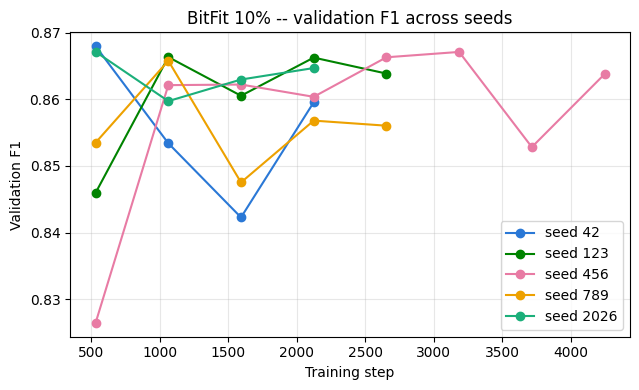

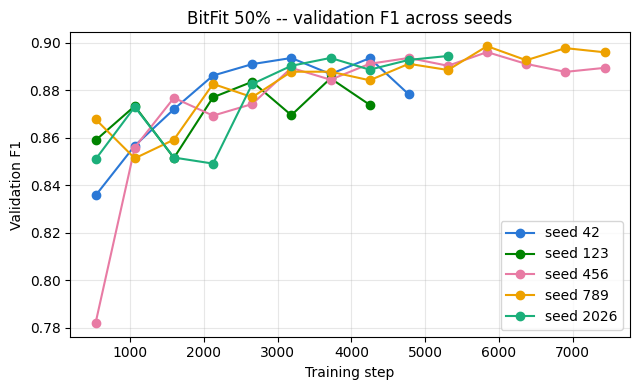

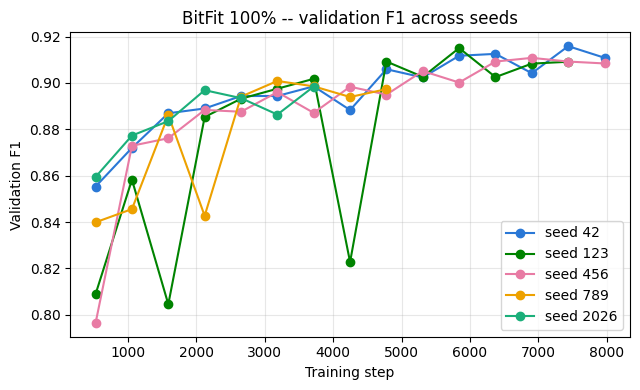

In [9]:
for size in sorted(RUN_SIZES):
    plot_seeds_overlay(METHOD_NAME, size, tag=TAG)

### Confusion matrices
Pooled over seeds, one per data size.

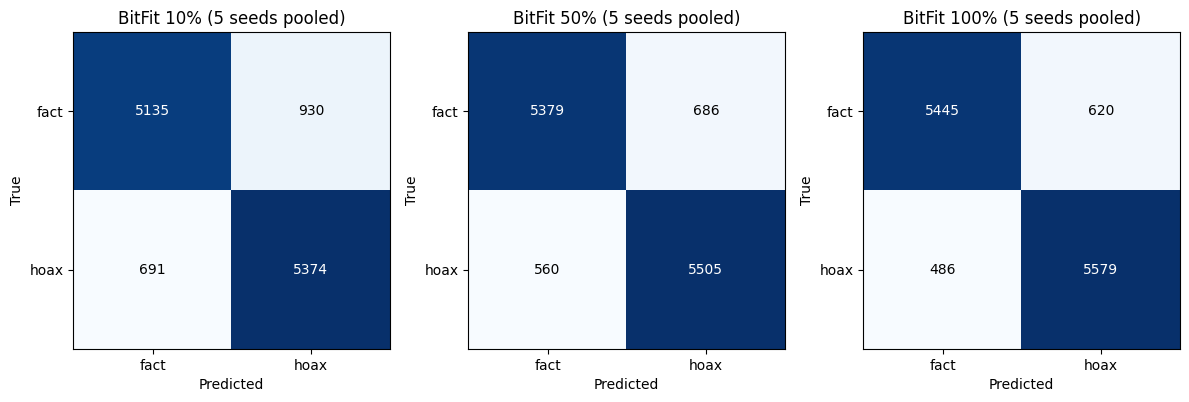

In [10]:
plot_confusion_matrices_by_size(METHOD_NAME, tag=TAG)

### Summary by data size
Mean +/- std over seeds: test vs. validation F1, generalization gap, training time.

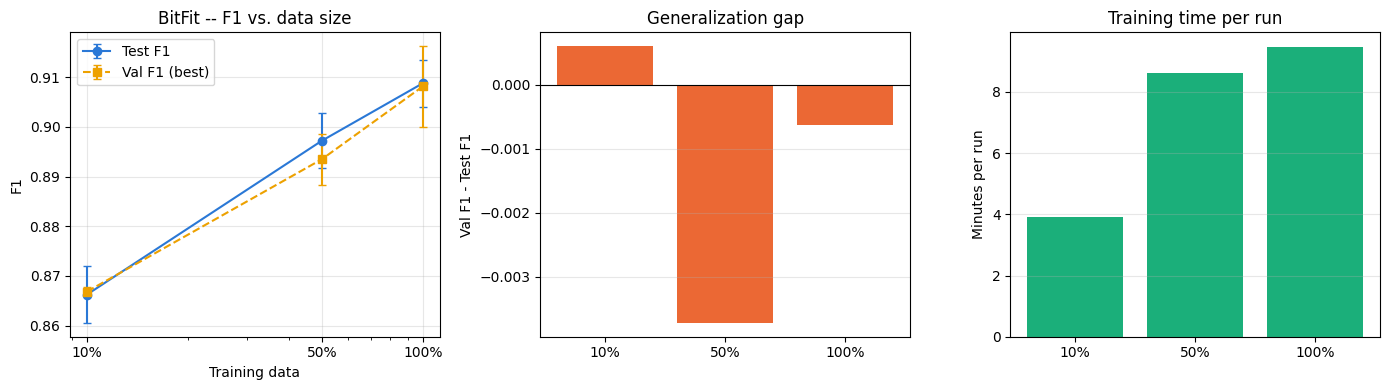

 data_size  seed  best_val_f1  accuracy       f1  trainable_pct  peak_vram_gb  total_time_s  epochs_run  steps_run
        10    42       0.8680  0.863149 0.863145         0.0839         0.721         206.4           4       2124
        10   123       0.8663  0.871393 0.871388         0.0839         0.721         305.5           5       2655
        10   456       0.8671  0.861088 0.861071         0.0839         0.721         311.7           8       4248
        10   789       0.8658  0.862737 0.862285         0.0839         0.721         202.0           5       2655
        10  2026       0.8671  0.873454 0.873414         0.0839         0.721         149.0           4       2124
        50    42       0.8935  0.894477 0.894466         0.0839         0.789         448.3           9       4779
        50   123       0.8850  0.889118 0.888784         0.0839         0.789         456.5           8       4248
        50   456       0.8960  0.901896 0.901887         0.0839         0.789   

In [11]:
plot_method_summary(METHOD_NAME, tag=TAG)